# 00 · Ejecutar todo el proyecto, paso a paso

**Clasificación automática de normativa sobre IA en educación superior de ALC · Proyecto Integrador · UEES · Grupo 9**

Este cuaderno reproduce el proyecto de principio a fin. Cada paso es una celda independiente que **omite el trabajo ya hecho** (si el artefacto existe no lo recalcula), de modo que puede ejecutarse completo (*Run All*) o celda por celda. Al terminar, el repositorio contiene las particiones, los dos modelos, la optimización, la evaluación final, la auditoría de equidad y las pruebas; la última celda lanza la aplicación web.

| Paso | Qué hace | Tiempo aprox. | Artefactos |
|---|---|---|---|
| 0 | Verifica entorno, dependencias y archivos de datos | segundos | — |
| 1 | Prepara el corpus (hash, limpieza, idioma, duplicados) y las particiones | 10 s | `data/processed/`, `data/splits/` |
| 2 | Optimiza hiperparámetros (Optuna, 60 ensayos) — *opcional, se reutiliza si ya existe* | 6 min | `results/metrics/optimizacion/`, figuras 13-17 |
| 3 | Entrena `model_v1` (base) y `best_model` (optimizado) | 20 s | `models/*.pkl` |
| 4 | Evalúa ambos modelos en el conjunto ciego | 30 s | `results/metrics/evaluacion_final.*` |
| 5 | Auditoría de equidad por jurisdicción | 20 s | `results/metrics/fairness/`, figura 12 |
| 6 | Pruebas automatizadas (`pytest`) | 30 s | — |
| 7 | Rama LLM *few-shot* — *opcional, requiere clave de API* | 10 min | `results/metrics/pred_llm*.csv` |
| 8 | Lanza la aplicación Streamlit | — | http://localhost:8501 |

**Requisitos previos.** Python ≥ 3.11; el archivo autorizado `consolidado_limpio.xlsx` en `data/raw/` y, si se dispone de él, `codificacion_investigador_A.xlsx` en la misma carpeta (sin él, la partición ciega se hace por muestreo estratificado). Ninguno de los dos se versiona.

> Abra este cuaderno desde la carpeta `notebooks/` del repositorio (JupyterLab, VS Code o Jupyter Notebook): la primera celda localiza la raíz automáticamente.

## Paso 0 · Entorno

Localiza la raíz del repositorio, comprueba la versión de Python y las dependencias. Si falta alguna, cambie `INSTALAR = True` y vuelva a ejecutar la celda (instala `requirements.txt` con el `pip` del propio kernel).

In [1]:
INSTALAR = False          # True → pip install -r requirements.txt desde este kernel
import importlib, sys, os, subprocess, json, time
import numpy as np, pandas as pd
from IPython.display import display, Image
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
assert (ROOT / "config.yaml").exists(), "No encuentro config.yaml: abra el cuaderno desde la carpeta notebooks/ del repositorio"
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
print("raíz:", ROOT); print("python:", sys.version.split()[0], "·", sys.executable)
assert sys.version_info >= (3, 11), "Se requiere Python 3.11 o superior"
if INSTALAR:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True); print("dependencias instaladas")
faltan = []
for mod, pip_name in [("pandas", "pandas"), ("numpy", "numpy"), ("sklearn", "scikit-learn"), ("joblib", "joblib"), ("yaml", "PyYAML"), ("openpyxl", "openpyxl"),
                      ("lingua", "lingua-language-detector"), ("matplotlib", "matplotlib"), ("optuna", "optuna"), ("streamlit", "streamlit"), ("plotly", "plotly"), ("pytest", "pytest")]:
    try:
        m = importlib.import_module(mod); print(f"  ✓ {pip_name:28s} {getattr(m, '__version__', '')}")
    except ImportError:
        faltan.append(pip_name); print(f"  ✗ {pip_name:28s} FALTA")
print("\nTodo listo." if not faltan else f"\nFaltan: {faltan} → ponga INSTALAR = True y vuelva a ejecutar esta celda.")

raíz: /home/claude/repo_genial
python: 3.11.15 · /usr/bin/python3
  ✓ pandas                       3.0.2
  ✓ numpy                        2.4.4


  ✓ scikit-learn                 1.8.0
  ✓ joblib                       1.5.3
  ✓ PyYAML                       6.0.3
  ✓ openpyxl                     3.1.5
  ✓ lingua-language-detector     


  ✓ matplotlib                   3.10.9
  ✓ optuna                       5.0.0


/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  ✓ streamlit                    1.65.0
  ✓ plotly                       7.1.0
  ✓ pytest                       9.1.1

Todo listo.


### Archivos de datos

El pipeline se detiene si el hash SHA-256 del corpus no coincide con el congelado en `config.yaml` (garantía de que todos trabajamos sobre la misma versión).

In [2]:
from utils import load_config, sha256_of, setup_logging, set_seed
cfg = load_config(); set_seed(cfg["seed"]); setup_logging()
RES = ROOT / "results/metrics"; FIG = ROOT / "results/figures"
raw = ROOT / cfg["paths"]["raw_corpus"]; instr = ROOT / "data/raw/codificacion_investigador_A.xlsx"
print("corpus autorizado      :", raw, "→", "existe" if raw.exists() else "NO EXISTE (cópielo en data/raw/)")
if raw.exists():
    h = sha256_of(raw); print("  SHA-256:", h[:16] + "…", "✓ coincide" if h == cfg["corpus_sha256"] else "✗ NO coincide con config.yaml")
print("instrumento del investigador:", instr.name, "→", "existe (la prueba ciega serán sus normas)" if instr.exists() else "no existe (prueba ciega por muestreo estratificado)")
FLAGS = dict(REHACER_PARTICIONES=False,   # True → vuelve a generar data/processed y data/splits aunque existan
             EJECUTAR_OPTUNA=False,       # True → corre los 60 ensayos aunque exista results/metrics/optimizacion/resumen.json (~6 min)
             N_TRIALS=60,
             EJECUTAR_LLM=False)          # True → rama LLM few-shot (necesita clave de API; ~10 min y coste de API)
FLAGS

corpus autorizado      : /home/claude/repo_genial/data/raw/consolidado_limpio.xlsx → existe
  SHA-256: f9797147e7026f79… ✓ coincide
instrumento del investigador: codificacion_investigador_A.xlsx → existe (la prueba ciega serán sus normas)


{'REHACER_PARTICIONES': False,
 'EJECUTAR_OPTUNA': False,
 'N_TRIALS': 60,
 'EJECUTAR_LLM': False}

## Paso 1 · Preparar el corpus y las particiones

`prepare_corpus()` carga el Excel, verifica el hash, normaliza, construye el texto (`título. observaciones`), detecta el idioma, marca duplicados por URL y escribe `data/processed/corpus_depurado.csv` más `results/metrics/reporte_calidad.md`. `make_partitions()` separa entrenamiento (673), pool *few-shot* (15) y prueba ciega (125, las normas del instrumento del investigador con sus duplicados). Las etiquetas de la prueba quedan en `test_labels_hidden.csv` y **solo se leen en el paso 4**.

In [3]:
from data_processing import prepare_corpus, make_partitions, load_splits, load_processed, describe
splits_dir = ROOT / cfg["paths"]["splits_dir"]
if FLAGS["REHACER_PARTICIONES"] or not (splits_dir / "train.csv").exists():
    df = prepare_corpus(cfg); splits, origen = make_partitions(df, cfg); print("particiones generadas ·", origen)
else:
    print("particiones ya existentes en", splits_dir, "(REHACER_PARTICIONES = True para regenerarlas)")
sp = load_splits(cfg); corpus = load_processed(cfg)
print({k: len(v) for k, v in sp.items()}); print(json.dumps(describe(corpus, cfg), ensure_ascii=False, indent=1))

particiones ya existentes en /home/claude/repo_genial/data/splits (REHACER_PARTICIONES = True para regenerarlas)
{'train': 673, 'fewshot': 15, 'test': 125}
{
 "n": 813,
 "clases": {
  "Pedagógico": 294,
  "Ética": 265,
  "Administrativo": 120,
  "Protección de Datos": 71,
  "Técnico": 63
 },
 "desbalance": 4.67,
 "idioma": {
  "es": 712,
  "pt": 76,
  "en": 25
 },
 "paises": 28,
 "palabras_mediana": 44.0,
 "palabras_media": 50.9,
 "grupos_url_repetidos": 14
}


## Paso 2 · Optimización de hiperparámetros (opcional)

Búsqueda bayesiana (Optuna, TPE, 60 ensayos) del F1 macro en validación cruzada por grupo sobre el conjunto de entrenamiento, seguida de importancia fANOVA, dependencia parcial, interacción `C × max_features`, tabla de sensibilidad y comparación antes/después. Tarda unos seis minutos; si `results/metrics/optimizacion/resumen.json` ya existe se reutiliza. El detalle comentado está en `04_optimizacion.ipynb`.

In [4]:
resumen_opt = ROOT / "results/metrics/optimizacion/resumen.json"
if FLAGS["EJECUTAR_OPTUNA"] or not resumen_opt.exists():
    t0 = time.time(); r = subprocess.run([sys.executable, "scripts/optimizar.py", "--trials", str(FLAGS["N_TRIALS"])], capture_output=True, text=True)
    print(r.stdout[-3000:]); print(r.stderr[-1500:] if r.returncode else f"optimización terminada en {time.time()-t0:.0f} s")
else:
    print("optimización ya existente (EJECUTAR_OPTUNA = True para repetirla)")
r = json.loads(resumen_opt.read_text(encoding="utf-8"))
print("configuración base      :", r["base"], "→ val F1 %.3f · gap %.2f" % (r["base_cv"]["val_f1"], r["base_cv"]["gap"]))
print("mejor ensayo Optuna     :", r["mejor"], "→ val F1 %.3f · gap %.2f" % (r["mejor_cv"]["val_f1"], r["mejor_cv"]["gap"]))
print("regla 1-DE (elegida)    :", r["regla_1se"], "→ val F1 %.3f · gap %.2f" % (r["regla_1se_cv"]["val_f1"], r["regla_1se_cv"]["gap"]))

optimización ya existente (EJECUTAR_OPTUNA = True para repetirla)
configuración base      : {'C': 1.0, 'max_features': 5000, 'ngram_max': 2, 'min_df': 1, 'class_weight': 'balanced', 'sublinear_tf': True} → val F1 0.547 · gap 0.40
mejor ensayo Optuna     : {'C': 3.041348095884574, 'max_features': 8000, 'ngram_max': 2, 'min_df': 1, 'class_weight': 'balanced', 'sublinear_tf': True} → val F1 0.553 · gap 0.44
regla 1-DE (elegida)    : {'C': 0.15671405527982937, 'max_features': 2000, 'ngram_max': 2, 'min_df': 1, 'class_weight': 'balanced', 'sublinear_tf': True} → val F1 0.540 · gap 0.27


## Paso 3 · Entrenar y guardar los modelos

`src/train.py` entrena con `train.csv` el modelo base (`model_v1.pkl`) y el optimizado (`best_model.pkl`, hiperparámetros de la regla 1-DE), cada uno con su `.json` de metadatos (hash del corpus, métricas de validación cruzada, fecha) y con su **umbral de confianza calibrado** (menor umbral que da ≥ 85 % de exactitud en el tramo automático sobre predicciones fuera de muestra).

In [5]:
import train as T
T.main(prepare=False, which="both")
print(json.dumps(json.loads((ROOT / "models/entrenamiento.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=1)[:1800])

2026-10-11 04:05:39,109 · INFO · model · modelo guardado en /home/claude/repo_genial/models/model_v1.pkl


2026-10-11 04:05:39,111 · INFO · train · model_v1: CV val F1 0.547 (gap 0.40) · umbral de confianza 0.50 (tramo automático 14 %, exactitud 0.87) · guardado


2026-10-11 04:05:40,802 · INFO · model · modelo guardado en /home/claude/repo_genial/models/best_model.pkl


2026-10-11 04:05:40,803 · INFO · train · best_model: CV val F1 0.540 (gap 0.27) · umbral de confianza 0.29 (tramo automático 15 %, exactitud 0.85) · guardado


{
 "model_v1": {
  "nombre": "model_v1",
  "origen_parametros": "configuración base del documento técnico",
  "n_entrenamiento": 673,
  "cv_por_grupo": {
   "val_f1": 0.5470230127438471,
   "val_std": 0.020186637826681078,
   "train_f1": 0.942325936883811,
   "gap": 0.39530292413996393
  },
  "f1_entrenamiento": 0.9223208566262884,
  "umbral_confianza": 0.5,
  "calibracion_umbral": {
   "criterio": "exactitud del tramo automático ≥ 0.85 con ≥ 10% de normas automáticas (CV por grupo, train)",
   "objetivo_alcanzado": true,
   "umbral": 0.5,
   "fraccion_automatica": 0.13967310549777118,
   "exactitud_automatica": 0.8723404255319149,
   "curva": [
    {
     "umbral": 0.2,
     "fraccion_automatica": 1.0,
     "exactitud_automatica": 0.5943536404160475
    },
    {
     "umbral": 0.25,
     "fraccion_automatica": 0.9791976225854383,
     "exactitud_automatica": 0.6009104704097117
    },
    {
     "umbral": 0.3,
     "fraccion_automatica": 0.8068350668647846,
     "exactitud_automatica":

## Paso 4 · Evaluación final en el conjunto ciego

Único punto del flujo donde se leen las etiquetas ocultas. Exactitud e IC de Wilson, F1 macro e IC *bootstrap* (2 000 remuestreos), top-2, κ frente a la etiqueta del codificador, McNemar frente a la clase mayoritaria y entre los dos modelos.

In [6]:
import evaluate as EV
tabla, detalle = EV.evaluate_models(["model_v1", "best_model"], cfg)
display(tabla.round(3))
print("McNemar model_v1 vs best_model:", {k: round(v, 3) if isinstance(v, float) else v for k, v in detalle["mcnemar_entre_modelos"].items()})

,modelo,n,exactitud,IC95 exactitud,F1 macro,IC95 F1 macro,top-2,kappa,McNemar vs mayoritaria p,F1 Pedagógico,F1 Ética,F1 Administrativo,F1 Protección de Datos,F1 Técnico
0,model_v1,125,0.688,"(0.6021982442599294, 0.7625911677057398)",0.617,"(0.5053799550431143, 0.7117515242005498)",0.872,0.555,0.0,0.779,0.725,0.345,0.737,0.500
1,best_model,125,0.672,"(0.5856431320533967, 0.7481003725109391)",0.631,"(0.5302096525380383, 0.7240072578656908)",0.864,0.542,0.0,0.737,0.714,0.333,0.800,0.571


McNemar model_v1 vs best_model: {'a': 'model_v1', 'b': 'best_model', 'n01': 6, 'n10': 4, 'statistic': nan, 'p_value': 0.754, 'method': 'binomial exacta'}


## Paso 5 · Auditoría de equidad por jurisdicción

Desempeño por idioma, tamaño del país, región, ámbito y codificador (anonimizado) sobre las predicciones fuera de muestra de la validación cruzada por grupo (n = 813), con IC de Wilson, razón frente al grupo de referencia (regla de los cuatro quintos) y proporción que la regla de gobernanza envía a revisión humana. Si las predicciones de validación cruzada no existen, se generan primero.

auditoría ejecutada


,dimensión,grupo,n,exactitud,IC95 inf,IC95 sup,razón vs referencia,% a revisión humana (regla)
0,Idioma del título,en,25,0.360,0.202,0.555,0.544,1.000
1,Idioma del título,es,712,0.662,0.626,0.695,1.000,0.822
2,Idioma del título,pt,76,0.474,0.365,0.584,0.716,1.000
6,Región,Brasil,81,0.469,0.364,0.577,0.699,1.000
7,Región,Caribe,45,0.378,0.251,0.524,0.563,1.000
8,Región,Hispanoamérica continental,687,0.671,0.635,0.705,1.000,0.815


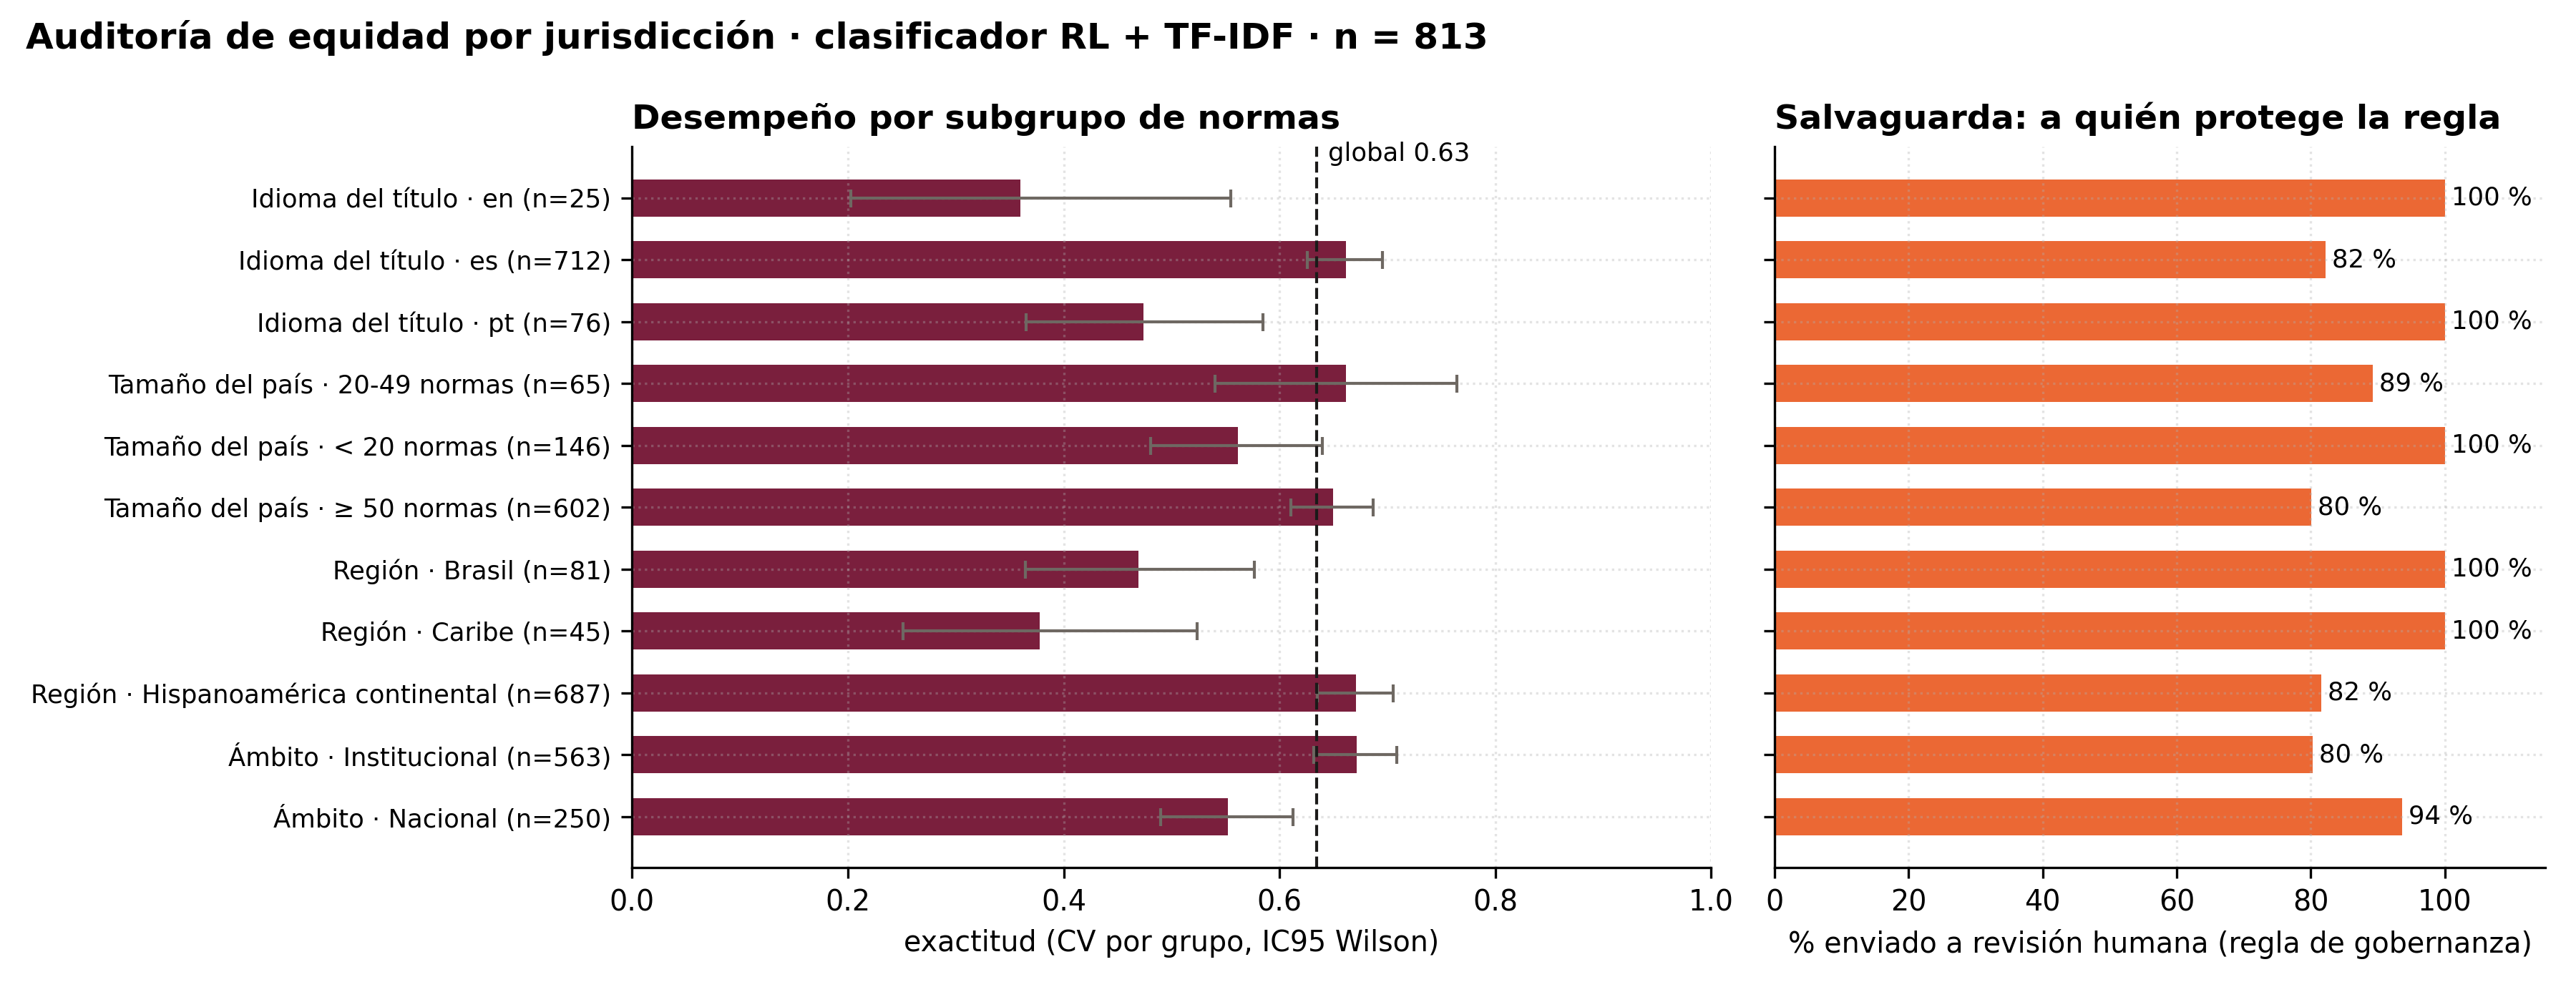

In [7]:
cvp = ROOT / "results/metrics/clasico_cv_predicciones.csv"
if not cvp.exists():
    from genial_clf import classic
    corpus = load_processed(cfg); p = classic.cross_validate(corpus, cfg)
    p.merge(corpus[["id_norma", "idioma", "País", "Ámbito", "Vínculo con Educación"]], on="id_norma").to_csv(cvp, index=False); print("predicciones de validación cruzada generadas")
r = subprocess.run([sys.executable, "scripts/fairness_grupos.py"], capture_output=True, text=True); print(r.stderr[-1200:] if r.returncode else "auditoría ejecutada")
fair = pd.read_csv(ROOT / "results/metrics/fairness/fairness_grupos.csv")
display(fair[fair["dimensión"].isin(["Idioma del título", "Región"])][["dimensión", "grupo", "n", "exactitud", "IC95 inf", "IC95 sup", "razón vs referencia", "% a revisión humana (regla)"]].round(3))
display(Image(filename=str(ROOT / "results/figures/12_fairness_grupos.png"), width=900))

## Paso 6 · Pruebas automatizadas

`tests/test_data_processing.py` (limpieza, texto, validación), `tests/test_model.py` (construcción, guardado, predicción, enrutamiento) y `tests/test_app.py` (la aplicación carga y responde, con `streamlit.testing`).

In [8]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_data_processing.py", "tests/test_model.py", "tests/test_app.py"], capture_output=True, text=True)
print(r.stdout[-2500:]); print(r.stderr[-800:] if r.returncode else "")

..............                                                           [100%]
14 passed in 4.84s




## Paso 7 · Rama LLM *few-shot* (opcional)

Clasifica el conjunto ciego con un modelo de lenguaje a temperatura 0, tres veces, con el *prompt* versionado en `prompts/clasificador_v0.1.md` y los 15 ejemplos del pool. Funciona con **Gemini** (`GEMINI_API_KEY`, gratuito con límites) o con **Anthropic** (`ANTHROPIC_API_KEY`). **Dónde va la clave:** la celda la busca, en este orden, en la variable de entorno, en `data/raw/gemini_key.txt` / `data/raw/anthropic_key.txt` (una sola línea con la clave) o en `.env` (`GEMINI_API_KEY=…`). Los tres lugares están fuera del control de versiones; **nunca pegue la clave en el cuaderno**. Ponga `FLAGS["EJECUTAR_LLM"] = True` para ejecutarla. Con la cuota gratuita de Gemini: `repeats: 1` (125 llamadas, ≈ 15 min con 6.5 s entre llamadas). Cada respuesta se guarda al instante en `pred_llm_parcial.csv`; si la cuota se agota a mitad, basta con **volver a ejecutar la celda más tarde** y continúa desde donde quedó.

### 7a · Guardar la clave de API sin escribirla en el cuaderno

Ejecute esta celda una sola vez: pide la clave con un cuadro oculto (`getpass`, no queda en la salida) y la guarda en `data/raw/gemini_key.txt`, que está en `.gitignore`. Si el archivo ya existe, no hace nada. Para Anthropic, cambie `PROVEEDOR = "anthropic"`.

In [9]:
PROVEEDOR = "gemini"            # "gemini" | "anthropic"
archivo_clave = ROOT / "data/raw" / f"{PROVEEDOR}_key.txt"
if FLAGS["EJECUTAR_LLM"] and not archivo_clave.exists():
    from getpass import getpass
    clave = getpass(f"Pegue la clave de {PROVEEDOR} y pulse Enter (no se muestra): ").strip()
    if clave:
        archivo_clave.write_text(clave + "\n", encoding="utf-8"); print("clave guardada en", archivo_clave.relative_to(ROOT), "(fuera del control de versiones)")
    else:
        print("no se guardó ninguna clave")
else:
    print("archivo de clave:", "existe" if archivo_clave.exists() else "no existe (ponga FLAGS['EJECUTAR_LLM'] = True y vuelva a ejecutar para introducirla)")

archivo de clave: no existe (ponga FLAGS['EJECUTAR_LLM'] = True y vuelva a ejecutar para introducirla)


In [10]:
def _buscar_api_key(var, archivo):
    k = os.environ.get(var, "").strip()
    if k: return k, "variable de entorno"
    for f, parse in [(ROOT / "data/raw" / archivo, lambda s: s.strip().splitlines()[0].strip() if s.strip() else ""),
                     (ROOT / ".env", lambda s: next((l.split("=", 1)[1].strip().strip('"').strip("'") for l in s.splitlines() if l.strip().startswith(var)), ""))]:
        if f.exists():
            k = parse(f.read_text(encoding="utf-8"))
            if k: return k, f.name
    return None, None

if FLAGS["EJECUTAR_LLM"]:
    proveedor = None
    for prov, var, archivo in [("gemini", "GEMINI_API_KEY", "gemini_key.txt"), ("anthropic", "ANTHROPIC_API_KEY", "anthropic_key.txt")]:
        key, origen = _buscar_api_key(var, archivo)
        if key:
            os.environ[var] = key; proveedor = prov; break
    if not proveedor:
        print("Sin clave de API: cree data/raw/gemini_key.txt (o anthropic_key.txt) con la clave en una sola línea, o defina GEMINI_API_KEY / ANTHROPIC_API_KEY.")
    else:
        from genial_clf import llm
        cfg_llm = {**cfg, "llm": {**cfg["llm"], "provider": proveedor}}
        clf = llm.make_classifier(cfg_llm)   # con model_gemini: auto consulta los modelos disponibles para la clave y elige el flash más reciente
        print(f"proveedor: {proveedor} · modelo: {clf.model} · clave leída de {origen} · {len(sp['test'])} normas × {cfg['llm']['repeats']} ejecuciones")
        cfg_llm["llm"]["model" if proveedor == "anthropic" else "model_gemini"] = clf.model
        preds_llm = llm.classify_blind(sp["test"], sp["fewshot"], cfg_llm, cfg["paths"]["prompt"], checkpoint=RES / "pred_llm_parcial.csv")
        if preds_llm.attrs.get("completo"):
            llm.save(preds_llm, RES / "pred_llm_runs.csv")
            preds_llm[preds_llm["run"] == 1][["id_norma", "pred", "pred_2"]].assign(conf=np.nan).to_csv(RES / "pred_llm.csv", index=False)
            print("rama LLM completa:", llm.stability(preds_llm), "· sin respuesta parseable:", int(preds_llm["pred"].isna().sum()), "· resultados en results/metrics/pred_llm.csv")
        else:
            print(f"rama LLM incompleta: {len(preds_llm)}/{preds_llm.attrs.get('total')} respuestas guardadas en results/metrics/pred_llm_parcial.csv. "
                  "La cuota de la API se agotó: vuelva a ejecutar esta celda más tarde (mañana si es cuota diaria) y continuará desde donde quedó.")
else:
    print("rama LLM omitida (FLAGS['EJECUTAR_LLM'] = False)." + (" Hay predicciones guardadas en results/metrics/pred_llm.csv." if (RES / "pred_llm.csv").exists() else ""))

rama LLM omitida (FLAGS['EJECUTAR_LLM'] = False).


## Paso 8 · Lanzar la aplicación web

La celda siguiente arranca Streamlit en segundo plano y abre http://localhost:8501 en el navegador. La aplicación carga `models/best_model.pkl`. Para detenerla ejecute la celda que sigue (o cierre el kernel).

In [11]:
import webbrowser
app_proc = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app/app.py", "--server.headless", "true", "--server.port", "8501", "--browser.gatherUsageStats", "false"],
                            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(4); print("aplicación en http://localhost:8501  (PID", app_proc.pid, ")")
if not os.environ.get("CI") and not os.environ.get("NBCONVERT"):
    webbrowser.open("http://localhost:8501")

aplicación en http://localhost:8501  (PID 521 )


In [12]:
# Detener la aplicación
if "app_proc" in globals() and app_proc.poll() is None:
    app_proc.terminate(); print("aplicación detenida")

aplicación detenida


## Resumen de artefactos generados

In [13]:
arte = ["data/processed/corpus_depurado.csv", "data/splits/train.csv", "data/splits/test_blind.csv", "data/splits/test_labels_hidden.csv",
        "results/metrics/optimizacion/resumen.json", "models/model_v1.pkl", "models/best_model.pkl", "results/metrics/evaluacion_final.csv",
        "results/metrics/fairness/fairness_grupos.csv", "results/figures/12_fairness_grupos.png", "results/figures/17_antes_despues_optimizacion.png", "results/metrics/pred_llm.csv"]
for a in arte:
    p = ROOT / a; print(("✓" if p.exists() else "·"), a, f"({p.stat().st_size/1024:.0f} KB)" if p.exists() else "(no generado)")

✓ data/processed/corpus_depurado.csv (785 KB)
✓ data/splits/train.csv (654 KB)
✓ data/splits/test_blind.csv (44 KB)
✓ data/splits/test_labels_hidden.csv (2 KB)
✓ results/metrics/optimizacion/resumen.json (4 KB)
✓ models/model_v1.pkl (401 KB)
✓ models/best_model.pkl (160 KB)
✓ results/metrics/evaluacion_final.csv (1 KB)
✓ results/metrics/fairness/fairness_grupos.csv (3 KB)
✓ results/figures/12_fairness_grupos.png (329 KB)
✓ results/figures/17_antes_despues_optimizacion.png (151 KB)
· results/metrics/pred_llm.csv (no generado)
